# 03 — Phân tích kết quả Decision Tree và Random Forest

## Mục tiêu
- So sánh Decision Tree và Random Forest.
- Phân tích Accuracy, Precision, Recall, F1 và ROC-AUC.
- Quan sát mức dao động của kết quả qua 5 fold.
- So sánh điểm train và validation để nhận diện dấu hiệu overfitting.
- Ghép với kết quả Logistic Regression và XGBoost ở notebook 02
  để hoàn thiện bảng baseline bốn mô hình.

Notebook sử dụng kết quả cross-validation trên tập train.
Tập test chưa được sử dụng để đánh giá.

In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.6 MB 6.7 MB/s eta 0:00:02
   --------- ------------------------------ 2.9/12.6 MB 7.0 MB/s eta 0:00:02
   -------------- ------------------------- 4.5/12.6 MB 7.3 MB/s eta 0:00:02
   ------------------- -------------------- 6.0/12.6 MB 7.2 MB/s eta 0:00:01
   ------------------------ --------------- 7.6/12.6 MB 7.2 MB/s eta 0:00:01
   ----------------------------- ---------- 9.2/12.6 MB 7.3 MB/s eta 0:00:01
   --------------------------------- ------ 10.5/12.6 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 7.2 MB/s  0:00:01
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ----- -----------------------------

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]

METRIC_LABELS = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1-score",
    "roc_auc": "ROC-AUC",
}

MODEL_LABELS = {
    "logistic_regression": "Logistic Regression",
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
}

In [6]:
current_dir = Path.cwd()

if (current_dir / "outputs" / "experiments").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "outputs" / "experiments").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Không tìm thấy outputs/experiments.")

# Lần chạy Decision Tree + Random Forest (notebook này).
RUN_ID = "baseline_20261029_111058_811513"

# Lần chạy Logistic Regression + XGBoost (notebook 02), dùng để so sánh.
BASELINE_RUN_ID = "baseline_20261029_170736_811841"

RUN_DIR = PROJECT_ROOT / "outputs" / "experiments" / RUN_ID
BASELINE_DIR = PROJECT_ROOT / "outputs" / "experiments" / BASELINE_RUN_ID

for directory in (RUN_DIR, BASELINE_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f"Không tìm thấy lần chạy: {directory}")

ANALYSIS_DIR = RUN_DIR / "analysis"
FIGURE_DIR = ANALYSIS_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Đang phân tích:", RUN_DIR.relative_to(PROJECT_ROOT))

Đang phân tích: outputs\experiments\baseline_20261029_111058_811513


In [7]:
comparison = pd.read_csv(RUN_DIR / "comparison.csv")
fold_results = pd.read_csv(RUN_DIR / "cv_results.csv")

with (RUN_DIR / "config.json").open(encoding="utf-8") as file:
    config = json.load(file)

print("Loại thực nghiệm:", config["experiment"])
print("Số fold:", config["n_splits"])
print("Random state:", config["random_state"])
print("Feature Engineering:", config["feature_engineering"])
print("Resampling:", config["resampling"])

display(comparison)
display(fold_results.head())

Loại thực nghiệm: baseline
Số fold: 5
Random state: 42
Feature Engineering: False
Resampling: None


,model,train_accuracy_mean,train_accuracy_std,val_accuracy_mean,val_accuracy_std,train_precision_mean,train_precision_std,val_precision_mean,val_precision_std,train_recall_mean,train_recall_std,val_recall_mean,val_recall_std,train_f1_mean,train_f1_std,val_f1_mean,val_f1_std,train_roc_auc_mean,train_roc_auc_std,val_roc_auc_mean,val_roc_auc_std,fit_time_seconds_mean
0,decision_tree,0.998314,0.000253,0.728611,0.00599,0.999496,0.000460,0.489011,0.010835,0.994147,0.001024,0.495652,0.014071,0.996814,0.000479,0.492165,0.008174,0.999992,0.000002,0.654318,0.005686,0.071999
1,random_forest,0.998314,0.000253,0.786299,0.00920,0.997656,0.001089,0.627603,0.026108,0.995987,0.000700,0.480268,0.021493,0.996820,0.000476,0.543877,0.019311,0.999936,0.000029,0.819857,0.011357,0.445703


,model,fold,fit_time_seconds,score_time_seconds,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc
0,decision_tree,1,0.118897,0.028223,0.998225,0.736469,0.99916,0.503448,0.994147,0.488294,0.996647,0.495756,0.999991,0.656573
1,decision_tree,2,0.062004,0.031307,0.998669,0.722272,1.00000,0.477564,0.994983,0.498328,0.997485,0.487725,0.999995,0.650128
2,decision_tree,3,0.051876,0.026682,0.998225,0.730257,0.99916,0.492063,0.994147,0.518395,0.996647,0.504886,0.999992,0.663336
3,decision_tree,4,0.060248,0.024808,0.998447,0.731145,0.99916,0.493151,0.994983,0.481605,0.997067,0.487310,0.999993,0.651118
4,decision_tree,5,0.066968,0.027555,0.998004,0.722913,1.00000,0.478827,0.992475,0.491639,0.996223,0.485149,0.999989,0.650433


In [8]:
assert not comparison["model"].duplicated().any()
assert not fold_results.duplicated(["model", "fold"]).any()

assert set(comparison["model"]) == set(fold_results["model"])

fold_counts = fold_results.groupby("model")["fold"].nunique()

assert fold_counts.eq(config["n_splits"]).all()

score_columns = [
    f"{split}_{metric}"
    for split in ["train", "val"]
    for metric in METRICS
]

assert fold_results[score_columns].notna().all().all()

print("Kết quả hợp lệ.")
display(fold_counts.rename("number_of_folds"))

Kết quả hợp lệ.


model
decision_tree    5
random_forest    5
Name: number_of_folds, dtype: int64

In [9]:
validation_table = pd.DataFrame({
    "Model": comparison["model"].map(MODEL_LABELS),
})

for metric in METRICS:
    validation_table[METRIC_LABELS[metric]] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            comparison[f"val_{metric}_mean"],
            comparison[f"val_{metric}_std"],
        )
    ]

display(validation_table)

validation_table.to_csv(
    ANALYSIS_DIR / "validation_summary.csv",
    index=False,
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.7286 ± 0.0060,0.4890 ± 0.0108,0.4957 ± 0.0141,0.4922 ± 0.0082,0.6543 ± 0.0057
1,Random Forest,0.7863 ± 0.0092,0.6276 ± 0.0261,0.4803 ± 0.0215,0.5439 ± 0.0193,0.8199 ± 0.0114


## So sánh kết quả validation

Các giá trị được trình bày dưới dạng trung bình ± độ lệch chuẩn
qua 5 fold.

- Random Forest đạt điểm validation cao hơn Decision Tree ở
  Accuracy, Precision, F1 và ROC-AUC.
- F1 của Random Forest là 0,5439; Decision Tree là 0,4922.
- ROC-AUC của Random Forest là 0,8199; Decision Tree chỉ đạt 0,6543.
- Recall của hai mô hình gần nhau (Decision Tree 0,4957; Random Forest
  0,4803) và chênh lệch nằm trong mức dao động giữa các fold, nên
  không thể nói mô hình nào phát hiện khách hàng rời bỏ tốt hơn.
- Khoảng cách ROC-AUC lớn hơn nhiều so với khoảng cách F1: Random
  Forest xếp hạng khách hàng theo nguy cơ rời bỏ tốt hơn rõ rệt,
  nhưng ở ngưỡng phân loại mặc định 0,5 thì phần lớn lợi thế đó
  chưa chuyển thành Recall.
- Độ lệch chuẩn mô tả dao động giữa các fold, không phải
  khoảng tin cậy.

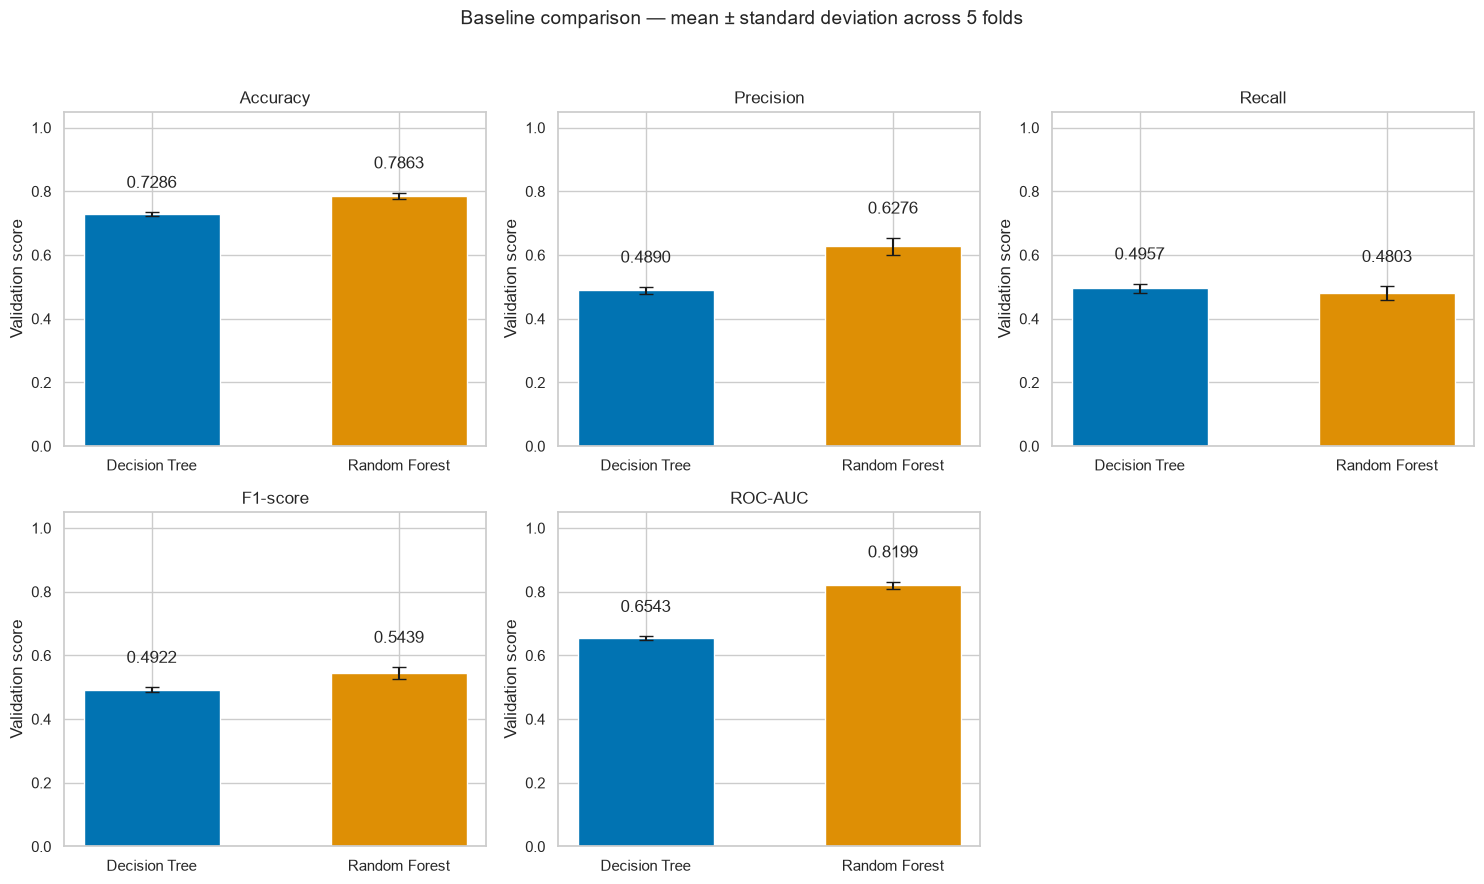

In [10]:
model_labels = comparison["model"].map(MODEL_LABELS).tolist()
colors = sns.color_palette("colorblind", n_colors=len(comparison))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, metric in zip(axes.flat, METRICS):
    means = comparison[f"val_{metric}_mean"].to_numpy()
    stds = comparison[f"val_{metric}_std"].to_numpy()

    bars = ax.bar(
        model_labels,
        means,
        yerr=stds,
        capsize=5,
        color=colors,
        width=0.55,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.4f}" for value in means],
        padding=15,
    )

    ax.set_title(METRIC_LABELS[metric])
    ax.set_ylabel("Validation score")
    ax.set_ylim(0, 1.05)

axes.flat[-1].axis("off")

fig.suptitle(
    "Baseline comparison — mean ± standard deviation across 5 folds",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    FIGURE_DIR / "validation_metrics.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [11]:
gap_table = comparison[
    [
        "model",
        "train_f1_mean",
        "val_f1_mean",
        "train_roc_auc_mean",
        "val_roc_auc_mean",
    ]
].copy()

gap_table["f1_gap"] = (
    gap_table["train_f1_mean"] - gap_table["val_f1_mean"]
)

gap_table["roc_auc_gap"] = (
    gap_table["train_roc_auc_mean"] - gap_table["val_roc_auc_mean"]
)

gap_table["model"] = gap_table["model"].map(MODEL_LABELS)

display(gap_table.round(4))

gap_table.to_csv(
    ANALYSIS_DIR / "train_validation_gaps.csv",
    index=False,
)

,model,train_f1_mean,val_f1_mean,train_roc_auc_mean,val_roc_auc_mean,f1_gap,roc_auc_gap
0,Decision Tree,0.9968,0.4922,1.0000,0.6543,0.5046,0.3457
1,Random Forest,0.9968,0.5439,0.9999,0.8199,0.4529,0.1801


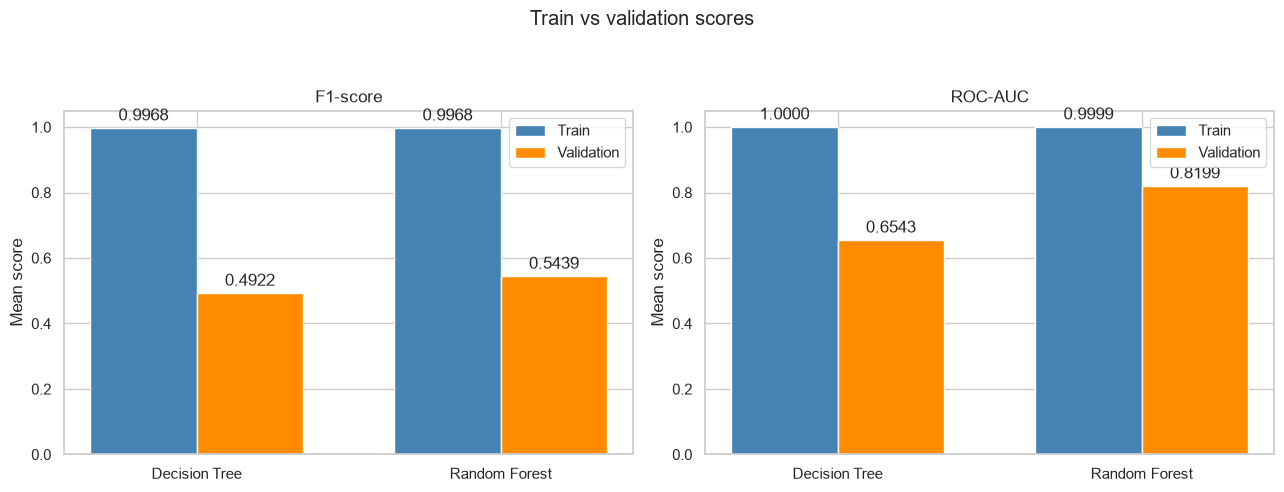

In [12]:
x = np.arange(len(comparison))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric in zip(axes, ["f1", "roc_auc"]):
    train_bars = ax.bar(
        x - width / 2,
        comparison[f"train_{metric}_mean"],
        width,
        label="Train",
        color="steelblue",
    )

    val_bars = ax.bar(
        x + width / 2,
        comparison[f"val_{metric}_mean"],
        width,
        label="Validation",
        color="darkorange",
    )

    ax.bar_label(train_bars, fmt="%.4f", padding=3)
    ax.bar_label(val_bars, fmt="%.4f", padding=3)

    ax.set_xticks(x)
    ax.set_xticklabels(model_labels)
    ax.set_title(METRIC_LABELS[metric])
    ax.set_ylabel("Mean score")
    ax.set_ylim(0, 1.05)
    ax.legend()

fig.suptitle("Train vs validation scores")
fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    FIGURE_DIR / "train_vs_validation.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Khoảng cách train và validation

Cả hai mô hình gần như ghi nhớ hoàn toàn tập huấn luyện: F1 train
khoảng 0,9968 và ROC-AUC train xấp xỉ 1,0000 ở cả Decision Tree lẫn
Random Forest.

Decision Tree có khoảng cách lớn nhất: F1 gap khoảng 0,5046 và
ROC-AUC gap khoảng 0,3457.

Random Forest có khoảng cách nhỏ hơn nhưng vẫn rất lớn: F1 gap khoảng
0,4529 và ROC-AUC gap khoảng 0,1801.

Đây là dấu hiệu overfitting rõ ở cả hai mô hình trong cấu hình
baseline: cây không giới hạn độ sâu nên phát triển đến khi mỗi lá gần
như thuần nhất. Việc lấy trung bình nhiều cây giúp Random Forest giảm
phương sai (ROC-AUC validation tăng từ 0,6543 lên 0,8199), nhưng từng
cây thành phần vẫn overfit nên khoảng cách train/validation vẫn lớn.

Điểm train gần như tuyệt đối không phản ánh chất lượng thật của mô hình
và không nên dùng để so sánh.

In [13]:
f1_by_fold = fold_results.pivot(
    index="fold",
    columns="model",
    values="val_f1",
).rename(columns=MODEL_LABELS)

auc_by_fold = fold_results.pivot(
    index="fold",
    columns="model",
    values="val_roc_auc",
).rename(columns=MODEL_LABELS)

print("Validation F1 theo fold:")
display(f1_by_fold.round(4))

print("Validation ROC-AUC theo fold:")
display(auc_by_fold.round(4))

Validation F1 theo fold:


model,Decision Tree,Random Forest
fold,,
1,0.4958,0.5488
2,0.4877,0.5437
3,0.5049,0.5618
4,0.4873,0.5115
5,0.4851,0.5536


Validation ROC-AUC theo fold:


model,Decision Tree,Random Forest
fold,,
1,0.6566,0.8185
2,0.6501,0.8077
3,0.6633,0.8211
4,0.6511,0.8140
5,0.6504,0.8380


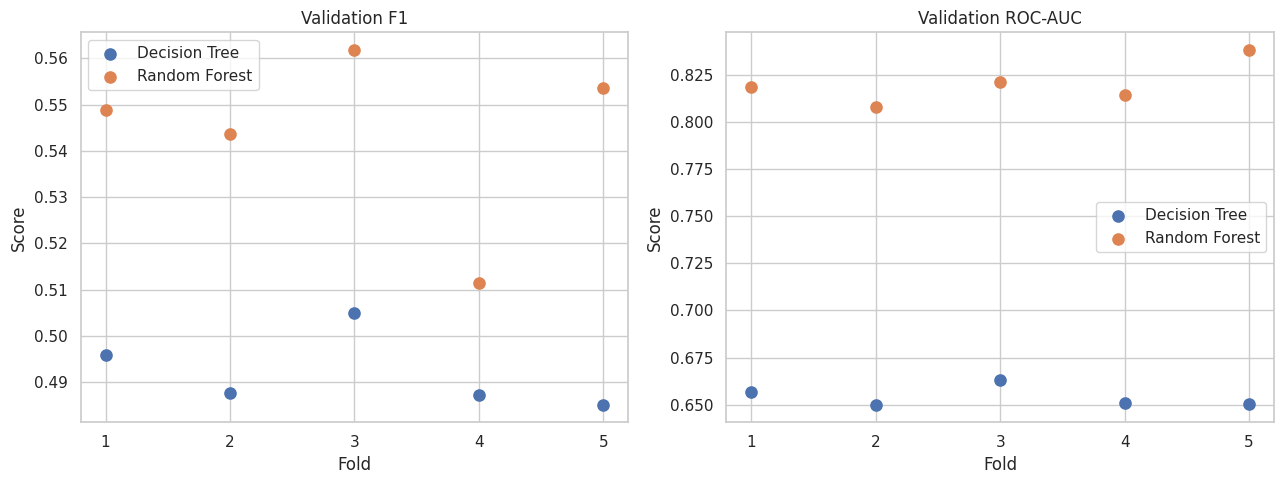

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, table, title in [
    (axes[0], f1_by_fold, "Validation F1"),
    (axes[1], auc_by_fold, "Validation ROC-AUC"),
]:
    for column in table.columns:
        ax.scatter(
            table.index,
            table[column],
            label=column,
            s=65,
        )

    ax.set_xticks(table.index)
    ax.set_xlabel("Fold")
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "validation_scores_by_fold.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Bảng baseline bốn mô hình

Phần này ghép kết quả của notebook 02 (Logistic Regression, XGBoost)
với kết quả ở trên (Decision Tree, Random Forest). Hai lần chạy dùng
cùng random state, cùng 5 fold Stratified và cùng 19 đặc trưng gốc
nên điểm validation so sánh trực tiếp được. Phần kiểm tra bên dưới
xác nhận điều kiện này.

In [11]:
baseline_comparison = pd.read_csv(BASELINE_DIR / "comparison.csv")

with (BASELINE_DIR / "config.json").open(encoding="utf-8") as file:
    baseline_config = json.load(file)

# Hai lần chạy chỉ so sánh được khi cùng cách chia fold và cùng đặc trưng.
for key in ["random_state", "n_splits", "train_rows", "input_features",
            "feature_engineering", "resampling"]:
    assert config[key] == baseline_config[key], key

all_models = pd.concat(
    [baseline_comparison, comparison],
    ignore_index=True,
)

assert not all_models["model"].duplicated().any()

print("Hai lần chạy cùng cấu hình chia fold và đặc trưng.")

all_table = pd.DataFrame({
    "Model": all_models["model"].map(MODEL_LABELS),
})

for metric in METRICS:
    all_table[METRIC_LABELS[metric]] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            all_models[f"val_{metric}_mean"],
            all_models[f"val_{metric}_std"],
        )
    ]

display(all_table)

all_table.to_csv(
    ANALYSIS_DIR / "validation_summary_all_models.csv",
    index=False,
)

Hai lần chạy cùng cấu hình chia fold và đặc trưng.


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8019 ± 0.0133,0.6524 ± 0.0294,0.5431 ± 0.0460,0.5921 ± 0.0334,0.8461 ± 0.0140
1,XGBoost,0.7982 ± 0.0088,0.6501 ± 0.0255,0.5204 ± 0.0235,0.5777 ± 0.0183,0.8413 ± 0.0084
2,Decision Tree,0.7286 ± 0.0060,0.4890 ± 0.0108,0.4957 ± 0.0141,0.4922 ± 0.0082,0.6543 ± 0.0057
3,Random Forest,0.7863 ± 0.0092,0.6276 ± 0.0261,0.4803 ± 0.0215,0.5439 ± 0.0193,0.8199 ± 0.0114


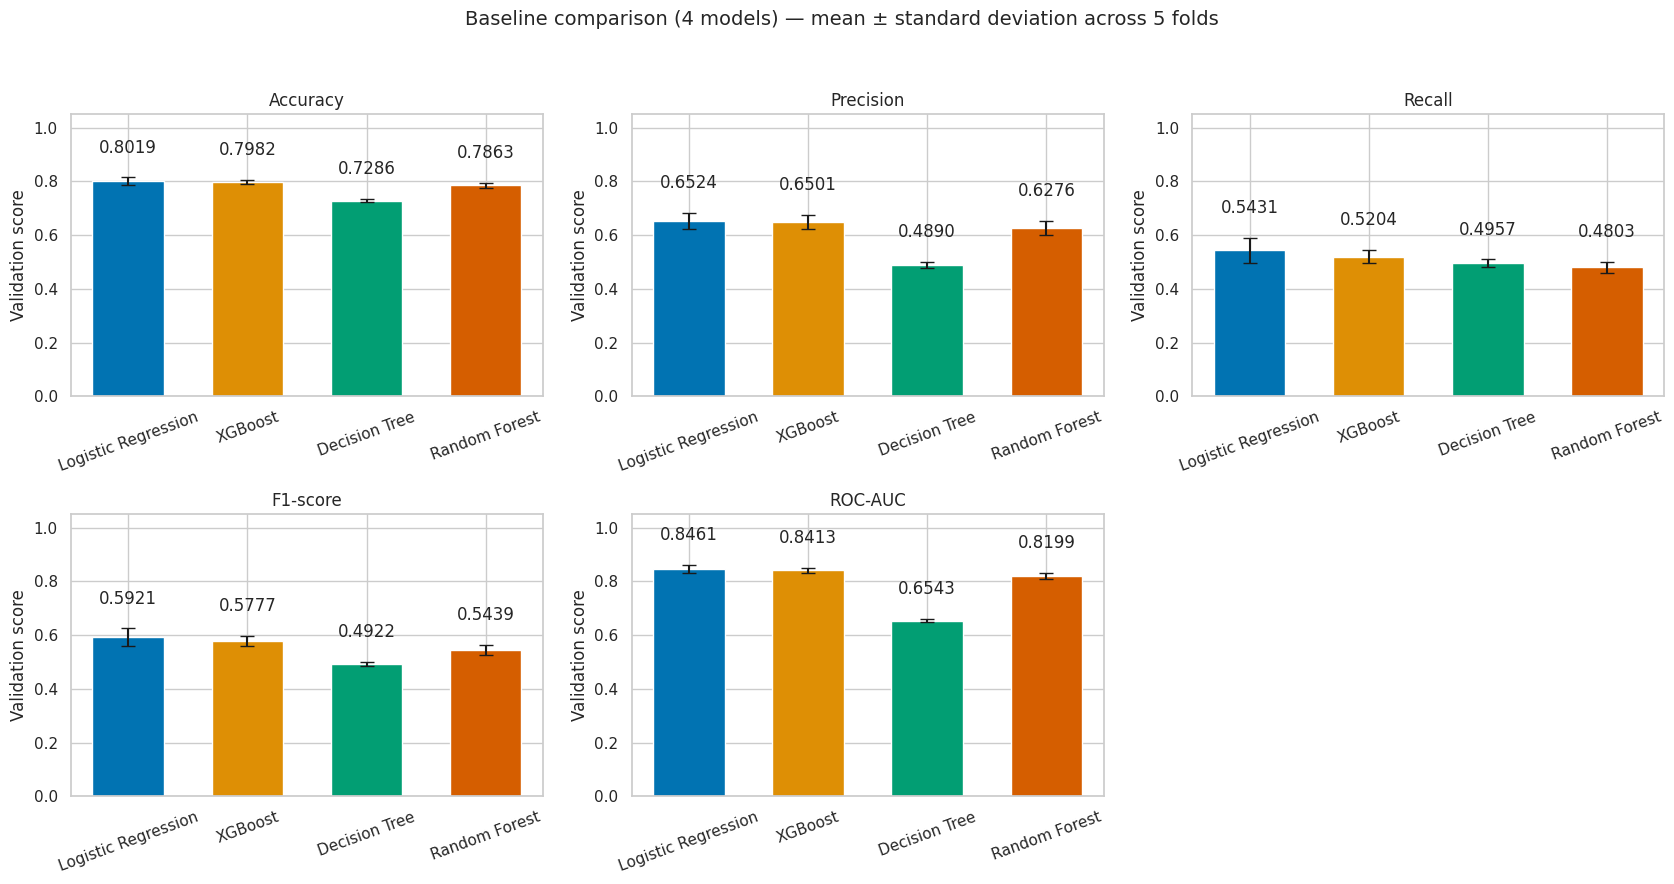

In [12]:
all_labels = all_models["model"].map(MODEL_LABELS).tolist()
all_colors = sns.color_palette("colorblind", n_colors=len(all_models))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, metric in zip(axes.flat, METRICS):
    means = all_models[f"val_{metric}_mean"].to_numpy()
    stds = all_models[f"val_{metric}_std"].to_numpy()

    bars = ax.bar(
        all_labels,
        means,
        yerr=stds,
        capsize=5,
        color=all_colors,
        width=0.6,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.4f}" for value in means],
        padding=15,
    )

    ax.set_title(METRIC_LABELS[metric])
    ax.set_ylabel("Validation score")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)

axes.flat[-1].axis("off")

fig.suptitle(
    "Baseline comparison (4 models) — mean ± standard deviation across 5 folds",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    FIGURE_DIR / "validation_metrics_all_models.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Kết luận baseline

### Kết quả chính

Thực nghiệm so sánh Decision Tree và Random Forest trên cùng
5 fold Stratified Cross-Validation với Logistic Regression và XGBoost,
sử dụng 19 đặc trưng gốc, chưa Feature Engineering, tuning hoặc xử lý
mất cân bằng.

Decision Tree đạt:
- Accuracy: 0,7286.
- Precision: 0,4890.
- Recall: 0,4957.
- F1: 0,4922.
- ROC-AUC: 0,6543.

Random Forest đạt:
- Accuracy: 0,7863.
- Precision: 0,6276.
- Recall: 0,4803.
- F1: 0,5439.
- ROC-AUC: 0,8199.

### Nhận xét

1. Random Forest tốt hơn Decision Tree rõ rệt ở ROC-AUC (0,8199 so với
   0,6543) và Precision; Recall của hai mô hình gần nhau.

2. Cả hai mô hình đều overfit nặng ở cấu hình mặc định: điểm train
   gần như tuyệt đối (F1 khoảng 0,9968) trong khi validation thấp hơn
   rất nhiều.

3. Trong bảng bốn mô hình, thứ tự theo F1 và ROC-AUC là Logistic
   Regression, XGBoost, Random Forest, Decision Tree. Các mô hình
   dựa trên cây chưa vượt được Logistic Regression ở cấu hình
   baseline.

4. Logistic Regression và XGBoost gần nhau. Random Forest thấp hơn
   khoảng 0,05 ở F1 và khoảng 0,026 ở ROC-AUC so với Logistic
   Regression; chênh lệch này lớn hơn độ lệch chuẩn giữa các fold
   nhưng mới dựa trên 5 fold, nên chưa đủ cơ sở kết luận chắc chắn.
   Decision Tree thấp hơn hẳn các mô hình còn lại.

5. Recall của cả bốn mô hình đều chỉ quanh mức 0,48–0,54 với ngưỡng
   phân loại mặc định, tức mới phát hiện được khoảng một nửa khách
   hàng thực sự rời bỏ. Đây là điểm cần cải thiện chung.

### Thực nghiệm tiếp theo

- Giới hạn độ phức tạp của cây (`max_depth`, `min_samples_leaf`) và của
  Random Forest để giảm overfitting; đây là cấu hình có nhiều khả
  năng cải thiện nhất cho hai mô hình này.
- So sánh trước và sau Feature Engineering.
- Tối ưu siêu tham số cho cả bốn mô hình bằng cross-validation trên
  tập train.
- Cân nhắc `class_weight` hoặc điều chỉnh ngưỡng trên validation
  nếu cần cải thiện Recall.

Các kết quả hiện tại là kết quả cross-validation trên tập train.
Tập test được giữ cho đánh giá cuối cùng.